# ROPE-TIEGCM demo: `use_da` and `use_f10_forecaster`

| `use_da` | `use_f10_forecaster` | IC from | F10 from | `uncertainty=True` gives |
|---|---|---|---|---|
| False | False | IC table | CSV | model spread (**old ROPE**, identical output) |
| True | False | data assimilation | CSV | model + IC (10-dim UT, 21 points) |
| False | True | IC table | forecaster after start | model + F10 (1-dim UT, 3 points) |
| True | True | data assimilation | forecaster after start | model + IC + F10 (11-dim UT, 23 points) |

* Set the switches in the constructor (`ROPE(use_da=True, ...)`) or per call (`rope.run(..., use_da=True)`).
* Optional **warm-up**: `ROPE(warmup_hours=48)` or `run(..., warmup_hours=48)` starts the IC-table run 48 h early on observed drivers and returns only the requested window (off by default; skipped with DA, whose IC is already the state at the start).
* DA ICs exist for **2024-03-01 .. 2024-07-31**, on 00/03/06/... UT starts.
* Drivers default to CelesTrak (1957..2026). `ROPE(drivers="tiegcm")` uses the TIE-GCM training drivers (1996..2009).
* Run from the repository root (see README for setup). A GPU is optional.

In [1]:
import os, sys, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())                 # repository root
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rope import ROPE

## 1. Old ROPE (both switches off)

In [2]:
rope = ROPE()                                    # use_da=False, use_f10_forecaster=False
START, H = "2024-05-10 18:00", 72

out = rope.run(START, horizon=H)                 # uncertainty=True by default
print(out["ic_source"], "|", out["f10_source"])
print("mean_density", out["mean_density"].shape, "  density_std", out["density_std"].shape, "   (hours, LST, lat, alt)")
out["window_df"].head()

I0000 00:00:1792073961.534740 3382496 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46315 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:41:00.0, compute capability: 8.6



ROPE ready  [drivers=sw_celestrack_1957_ap.csv.gz  use_da=False  use_f10_forecaster=False  device=cuda]



table | csv
mean_density (72, 72, 36, 45)   density_std (72, 72, 36, 45)    (hours, LST, lat, alt)


,datetime,f10,f10_41day_avg,ap
0,2024-05-10 18:00:00,216.125000,166.592619,300.000000
1,2024-05-10 19:00:00,215.720833,166.674805,300.000000
2,2024-05-10 20:00:00,215.316667,166.756834,300.000000
3,2024-05-10 21:00:00,214.912500,166.838707,300.000000
4,2024-05-10 22:00:00,214.508333,166.920423,333.333333


## 2. Switch DA and/or the F10 forecaster on

The same object works for every mode: per-call switches override the constructor. DA and the forecaster load on first use.

In [3]:
modes = {
    "old ROPE":              dict(use_da=False, use_f10_forecaster=False),
    "use_da":                dict(use_da=True,  use_f10_forecaster=False),
    "use_f10_forecaster":    dict(use_da=False, use_f10_forecaster=True),
    "use_da + forecaster":   dict(use_da=True,  use_f10_forecaster=True),
}
runs = {name: rope.run(START, horizon=H, **kw) for name, kw in modes.items()}

ALT = np.linspace(100, 980, 45); k = int(np.argmin(np.abs(ALT - 400)))
rows = []
for name, r in runs.items():
    rel = lambda a, h: 100 * np.median(a[h, ..., k] / r["mean_density"][h, ..., k])
    row = {"mode": name, "IC": r["ic_source"], "F10": r["f10_source"],
           "σ_F10 (sfu)": r.get("f10_sigma", np.nan)}
    for h in (0, 24, 48):
        row[f"total σ/ρ h{h} %"] = rel(r["density_std"], h)
    rows.append(row)
pd.DataFrame(rows).round(2)

Loaded model types: ['LSTM_dynamic'] (180 models cached, 1 loader threads)


,mode,IC,F10,σ_F10 (sfu),total σ/ρ h0 %,total σ/ρ h24 %,total σ/ρ h48 %
0,old ROPE,table,csv,NaN,0.92,31.73,12.69
1,use_da,da,csv,NaN,6.34,35.37,12.45
2,use_f10_forecaster,table,forecaster (LSTM_dynamic),14.09,0.92,42.47,13.48
3,use_da + forecaster,da,forecaster (LSTM_dynamic),14.09,6.34,43.59,12.92


## 3. Compare: global-mean density at 400 km, its absolute uncertainty, and the drivers each mode used

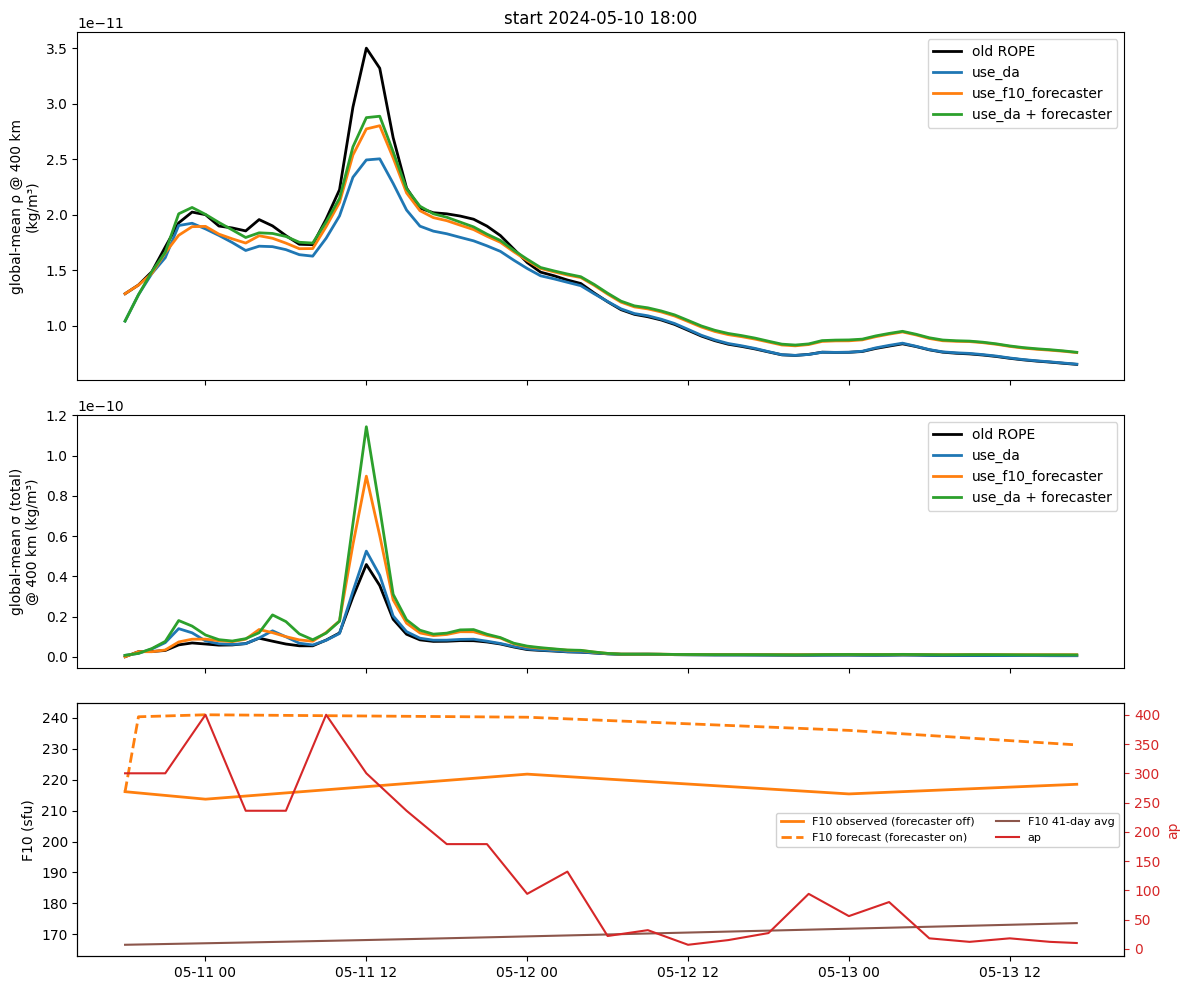

In [4]:
colors = {"old ROPE": "k", "use_da": "tab:blue", "use_f10_forecaster": "tab:orange", "use_da + forecaster": "tab:green"}
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.6, 1.6]})
gm = lambda a: a[..., k].reshape(a.shape[0], -1).mean(1)
for name, r in runs.items():
    t = r["window_df"].datetime
    ax[0].plot(t, gm(r["mean_density"]), color=colors[name], lw=2, label=name)
    ax[1].plot(t, gm(r["density_std"]), color=colors[name], lw=2, label=name)
ax[0].set_ylabel("global-mean ρ @ 400 km\n(kg/m³)"); ax[0].legend(); ax[0].set_title(f"start {START}")
ax[1].set_ylabel("global-mean σ (total)\n@ 400 km (kg/m³)"); ax[1].legend()
w  = runs["old ROPE"]["window_df"]                 # F10 from the CSV (observed)
wf = runs["use_f10_forecaster"]["window_df"]       # F10 from the forecaster after the start hour
ax[2].plot(w.datetime, w.f10, color="tab:orange", lw=2, label="F10 observed (forecaster off)")
ax[2].plot(wf.datetime, wf.f10, color="tab:orange", ls="--", lw=2, label="F10 forecast (forecaster on)")
ax[2].plot(w.datetime, w.f10_41day_avg, color="tab:brown", lw=1.5, label="F10 41-day avg")
ax[2].set_ylabel("F10 (sfu)")
ax_ap = ax[2].twinx()
ax_ap.plot(w.datetime, w.ap, color="tab:red", lw=1.5, label="ap")
ax_ap.set_ylabel("ap", color="tab:red"); ax_ap.tick_params(axis="y", colors="tab:red"); ax_ap.grid(False)
h1, l1 = ax[2].get_legend_handles_labels(); h2, l2 = ax_ap.get_legend_handles_labels()
ax[2].legend(h1 + h2, l1 + l2, fontsize=8, ncol=2, loc="center right", framealpha=0.9)
plt.tight_layout(); plt.show()

## 4. Optional warm-up

Without DA, the initial condition comes from the IC table, which is only an approximation of the state at the start.
`warmup_hours=48` starts the run 48 h earlier on observed drivers, so that error has faded by the start time; only the
requested window is returned. It is off by default, and skipped with DA (the assimilated state is the start itself).

warm-up used: 48 h | with DA: 0 h -> warm-up (48 h) skipped: the DA IC is the state at the start


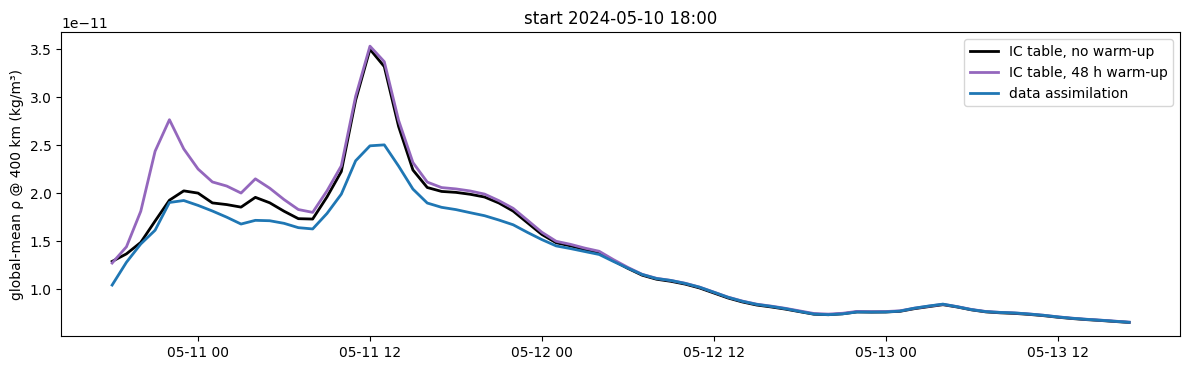

In [5]:
no_wu = runs["old ROPE"]
wu    = rope.run(START, horizon=H, warmup_hours=48)          # same call, 48 h warm-up
da_wu = rope.run(START, horizon=H, use_da=True, warmup_hours=48, uncertainty=False)
print("warm-up used:", wu["warmup_hours"], "h | with DA:", da_wu["warmup_hours"], "h ->", da_wu.get("warmup_note"))

fig, ax = plt.subplots(figsize=(12, 3.8))
for name, r_, c in (("IC table, no warm-up", no_wu, "k"), ("IC table, 48 h warm-up", wu, "tab:purple"),
                    ("data assimilation", runs["use_da"], "tab:blue")):
    ax.plot(r_["window_df"].datetime, gm(r_["mean_density"]), color=c, lw=2, label=name)
ax.set_ylabel("global-mean ρ @ 400 km (kg/m³)"); ax.legend(); ax.set_title(f"start {START}")
plt.tight_layout(); plt.show()

## 5. Where the uncertainty comes from (both switches on)

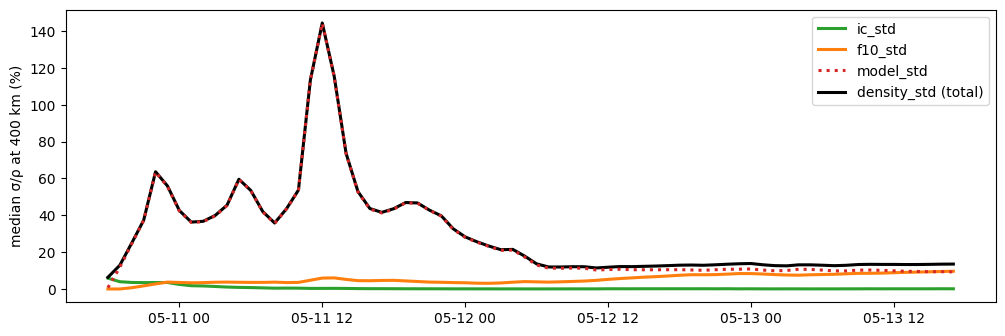

,date,f10_mean,f10_std
0,2024-05-10,237.91,11.92
1,2024-05-11,241.01,13.12
2,2024-05-12,240.22,14.72
3,2024-05-13,235.96,16.61
4,2024-05-14,229.33,19.20


In [6]:
r = runs["use_da + forecaster"]
t = r["window_df"].datetime
rel = lambda a: 100 * np.median((a[..., k] / r["mean_density"][..., k]).reshape(a.shape[0], -1), axis=1)
fig, ax = plt.subplots(figsize=(12, 3.8))
for key, c, ls in (("ic_std", "tab:green", "-"), ("f10_std", "tab:orange", "-"),
                   ("model_std", "tab:red", ":"), ("density_std", "k", "-")):
    ax.plot(t, rel(r[key]), color=c, ls=ls, lw=2.2, zorder=4 if key == "model_std" else 2,   # dotted on top
            label=key + (" (total)" if key == "density_std" else ""))
ax.set_ylabel("median σ/ρ at 400 km (%)"); ax.legend(); plt.show()
display(r["f10_forecast"].round(2))

## 6. Density at a point (e.g. along an orbit)

In [7]:
from interpolator import DensityInterpolator
q = DensityInterpolator(r)                       # works on any rope.run() output
q.query("2024-05-11 06:30", lst=14.0, lat=30.0, alt_km=450.0, time_mode="interp_time")

{'datetime': Timestamp('2024-05-11 06:30:00'),
 'density': 1.0587148454121624e-11,
 't_index_left': 12,
 't_index_right': 13,
 'datetime_left': Timestamp('2024-05-11 06:00:00'),
 'datetime_right': Timestamp('2024-05-11 07:00:00'),
 'time_weight_right': 0.5,
 'time_mode': 'interp_time',
 'alt_regime': 'grid_interpolation',
 'sigma': 3.2634716325212707e-12}

## 7. Your turn

Change these and rerun the cell. Options:
* `ROPE(..., ic_cov_scale=5)` inflates the DA σ (the filter σ is ~70x too small)
* `f10_model_type="MLP_dynamic"`
* `rope.run(..., f10_sigma=10)` uses a fixed F10 σ
* `uncertainty=False` gives a fast deterministic run
* `warmup_hours=48` spins up the IC-table start (ignored with DA)

In [8]:
my = rope.run("2024-06-15 03:00", horizon=48, use_da=False, use_f10_forecaster=True, warmup_hours=48)
print(my["ic_source"], "|", my["f10_source"], "| warm-up", my["warmup_hours"], "h | σ_F10 =", round(my["f10_sigma"], 2))
print("keys:", list(my))

table | forecaster (LSTM_dynamic) | warm-up 48 h | σ_F10 = 5.62
keys: ['window_df', 'mean_density', 'central_density', 'input_std', 'ic_std', 'f10_std', 'ic_latents', 'ic_mean', 'ic_cov', 'sigma_points', 'fused_latents', 'model_mean_density', 'model_std', 'total_std', 'density_std', 'ic_source', 'f10_source', 'warmup_hours', 'f10_forecast', 'f10_sigma']
